In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv(r'C:\Users\User\AppData\Local\Temp\d49da043-0ac2-4345-9259-7021fc754e30_archive.zip.e30\amz_uk_price_prediction_dataset.csv')
print(df.head())

   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  


In [4]:
df. isnull().sum()  

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [5]:
df. duplicated().sum()

0

Understanding Product Categories

In [9]:
category_counts = df['category'].value_counts()
print(category_counts)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


In [10]:
top_5_categories = category_counts.head(5)
print(top_5_categories)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


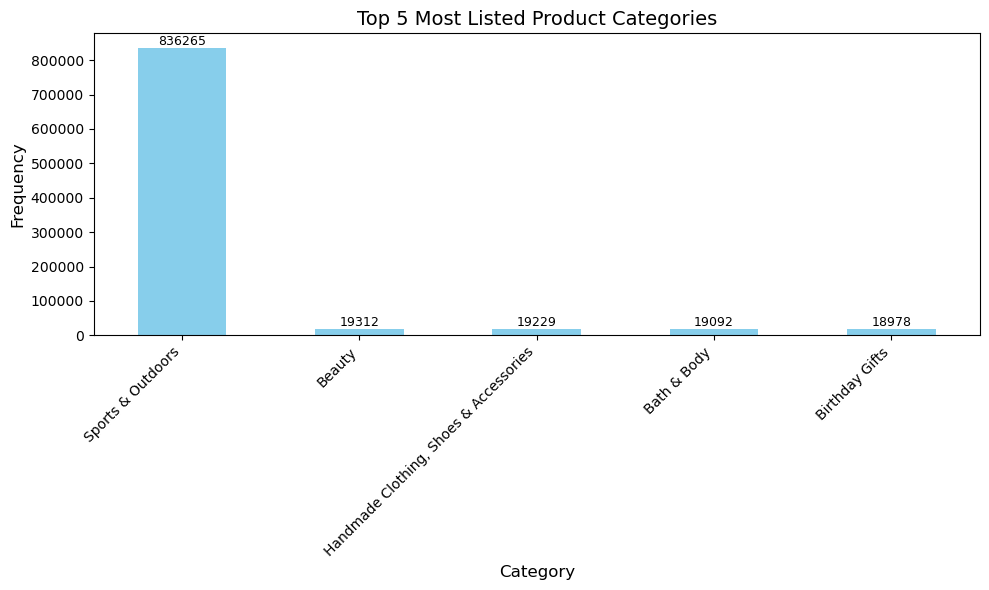

In [14]:
plt.figure(figsize=(10, 6))

# Create the bar plot
top_5_categories.plot(kind='bar', color='skyblue')

# Add labels and title
plt.title('Top 5 Most Listed Product Categories', fontsize=14)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Rotate x-ticks for better visibility
plt.xticks(rotation=45, ha='right', fontsize=10)
df['category'] = df['category'].str.title()
for i, value in enumerate(top_5_categories):
    plt.text(i, value, str(value), ha='center', va='bottom', fontsize=9)
# Display the bar plot
plt.tight_layout()  # Adjust the layout to avoid clipping
plt.show()

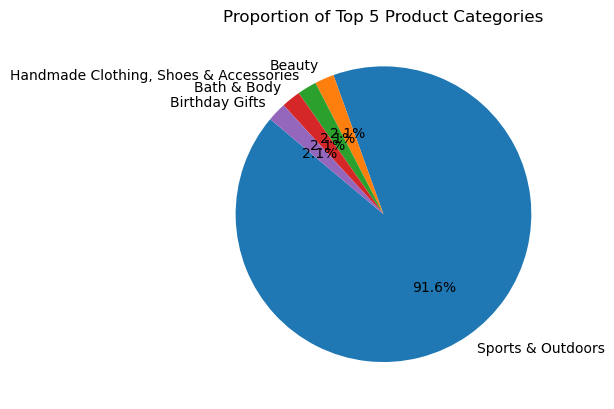

In [ ]:
top_5_categories.plot(kind='pie', autopct='%1.1f%%', startangle=140)
plt.title('Proportion of Top 5 Product Categories')
plt.ylabel('')  
plt.show()

Delving into Product Pricing

In [16]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]  # In case of multiple modes, take the first one

print(f"Mean Price: {mean_price}")
print(f"Median Price: {median_price}")
print(f"Mode Price: {mode_price}")

Mean Price: 89.24380943923663
Median Price: 19.09
Mode Price: 9.99


Mean is almost 9 times bigger then the mosst common price point (mode). 

Measures of Dispersion:

In [17]:
variance_price = df['price'].var()
std_dev_price = df['price'].std()
price_range = df['price'].max() - df['price'].min()
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr_price = q3 - q1

print(f"Variance: {variance_price}")
print(f"Standard Deviation: {std_dev_price}")
print(f"Range: {price_range}")
print(f"Interquartile Range (IQR): {iqr_price}")

Variance: 119445.48532256528
Standard Deviation: 345.60886175352226
Range: 100000.0
Interquartile Range (IQR): 36.0


Variance: Measures the spread of the prices.
Standard Deviation: Gives you a sense of how much prices deviate from the mean on average.
Range: Difference between maximum and minimum prices.
Interquartile Range (IQR): Range within which the middle 50% of prices lie, useful for understanding the spread around the median.

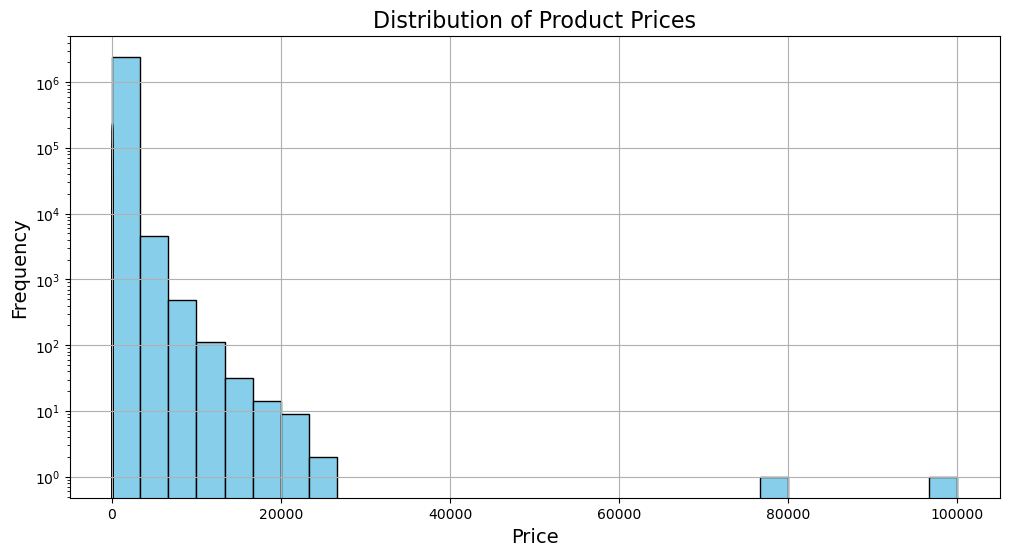

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Adjust the bins according to the distribution of your data
plt.hist(df['price'], bins=30, color='skyblue', edgecolor='black')
import numpy as np
df['log_price'] = np.log(df['price'] + 1)  # Adding 1 to avoid log(0) issues
plt.hist(df['log_price'], bins=50, color='skyblue', edgecolor='black')
# Do not use log if it doesn't help, or consider log distribution of data and plot normally
plt.yscale('log')
# Alternatively, try without the log scale to see if it's more readable:
# plt.xscale('log')

plt.title('Distribution of Product Prices', fontsize=16)
plt.xlabel('Price', fontsize=14)
plt.ylabel('Frequency', fontsize=14)

# Adding a grid for better readability
plt.grid(True)

plt.show()

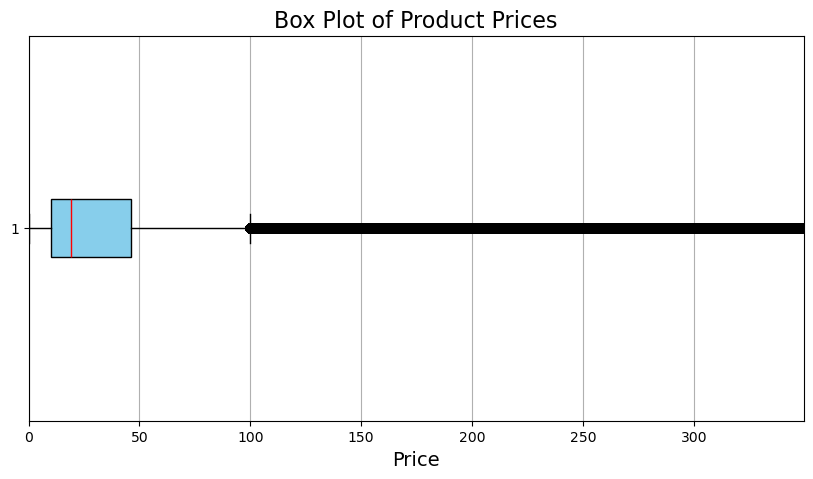

In [29]:
plt.figure(figsize=(10, 5))

plt.boxplot(df['price'], vert=False, patch_artist=True, 
            boxprops=dict(facecolor='skyblue', color='black'),
            medianprops=dict(color='red'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'))

plt.title('Box Plot of Product Prices', fontsize=16)
plt.xlabel('Price', fontsize=14)

# Optionally, set a limit on the x-axis if there are extreme outliers for better visualization
plt.xlim(0, df['price'].quantile(0.95))  # Focus up to the 95th percentile to zoom in

plt.grid(True)
plt.show()

Measures of Centrality:

In [34]:
# Unique values and their frequency for reviews
print("\nUnique Review Counts:")
print(df['reviews'].value_counts())

# Unique values and their frequency for stars
print("\nUnique Stars Counts:")
print(df['stars'].value_counts())


Unique Review Counts:
reviews
0         1225641
1           90033
2           54452
3           39922
4           30720
           ...   
13246           1
16044           1
25872           1
8503            1
547940          1
Name: count, Length: 19446, dtype: int64

Unique Stars Counts:
stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64


In [36]:
mean_stars = df['stars'].mean()
median_stars = df['stars'].median()
mode_stars = df['stars'].mode()[0]  # In case there are multiple modes, take the first one

# Print the statistics with proper references to the stars column
print(f"Mean Stars: {mean_stars}")
print(f"Median Stars: {median_stars}")
print(f"Mode Stars: {mode_stars}")

Mean Stars: 2.152836472966065
Median Stars: 0.0
Mode Stars: 0.0


Measures of Dispersion:

In [37]:
variance_stars = df['stars'].var()
std_dev_stars = df['stars'].std()
iqr_stars = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

# Print the statistics with proper references to the stars column
print(f"Variance of Stars: {variance_stars}")
print(f"Standard Deviation of Stars: {std_dev_stars}")
print(f"Interquartile Range (IQR) of Stars: {iqr_stars}")

Variance of Stars: 4.81743402976196
Standard Deviation of Stars: 2.1948653785054697
Interquartile Range (IQR) of Stars: 4.4


Shape of the Distribution:

In [38]:
skewness_stars = df['stars'].skew()
kurtosis_stars = df['stars'].kurtosis()

# Print the statistics with proper references to the stars column
print(f"Skewness of Stars: {skewness_stars}")
print(f"Kurtosis of Stars: {kurtosis_stars}")

Skewness of Stars: 0.08120735761080985
Kurtosis of Stars: -1.9260061280432985


Skewness: Measures the asymmetry of the distribution of star ratings.

A skewness near 0 suggests a symmetric distribution.
A positive skewness indicates that the tail is on the right-hand side (more low ratings).
A negative skewness indicates that the tail is on the left-hand side (more high ratings).
Kurtosis: Measures the "tailedness" of the distribution.

A kurtosis near 0 indicates a normal distribution (mesokurtic).
Positive kurtosis suggests a distribution with heavier tails and a sharper peak (leptokurtic).
Negative kurtosis suggests lighter tails and a flatter peak (platykurtic).

 Histogram for Product Ratings:

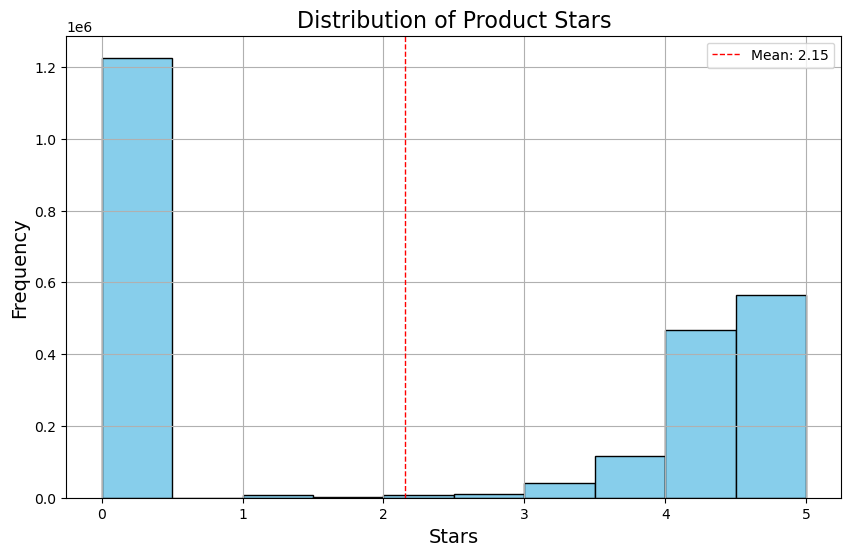

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot a histogram for the stars column
plt.hist(df['stars'], bins=10, color='skyblue', edgecolor='black')

# Set titles and labels
plt.title('Distribution of Product Stars', fontsize=16)
plt.xlabel('Stars', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
mean_stars = df['stars'].mean()
plt.axvline(mean_stars, color='red', linestyle='dashed', linewidth=1, label=f"Mean: {mean_stars:.2f}")
plt.legend()
# Add grid for better readability
plt.grid(True)

# Display the plot
plt.show()